[INFO] device = cuda
[INFO] hidden_dims = [256, 512, 256]
[INFO] max_n in test = 132


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_31924\1050180520.py:655: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


[INFO] Loaded model: best_model_in4_K4_256-512-256_testloss0.051024.pth
[INFO] Number of test samples = 500
[INFO] Selected samples:
  ps_test{28}.mat
  ps_test{1}.mat
  ps_test{78}.mat
[SAVED] test_x1_marginal_selected_samples_sci_roman.pdf


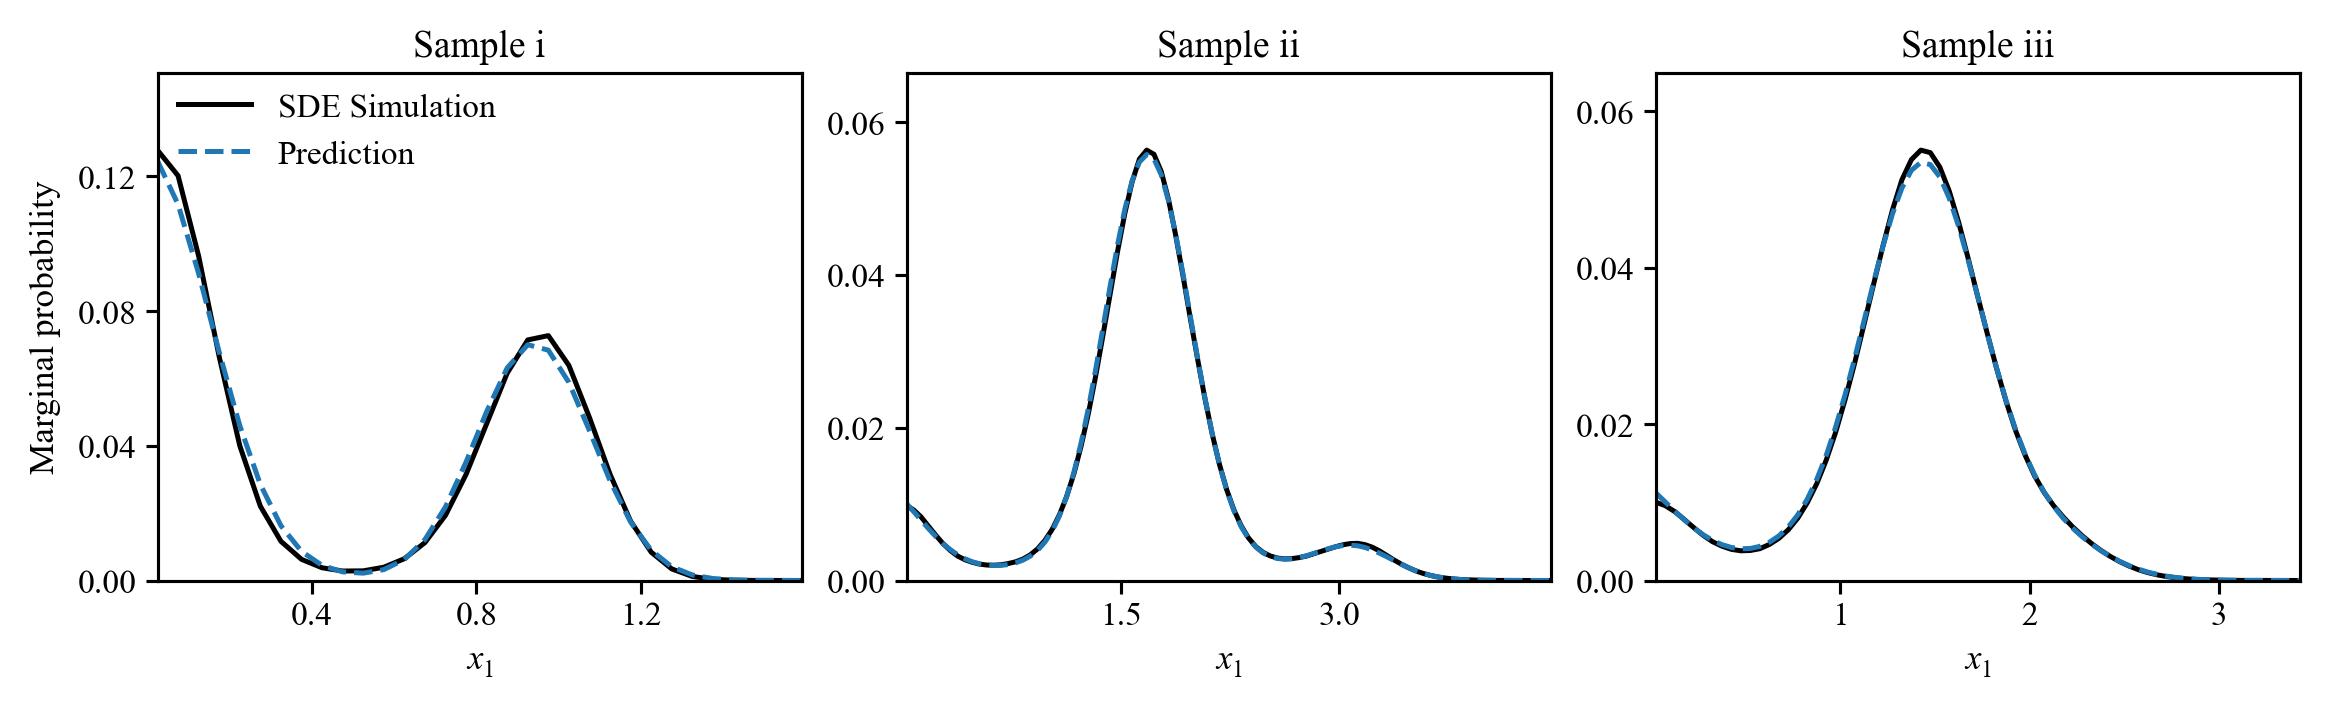

[DONE] Selected test-set x1 marginal distribution comparison finished.


In [1]:
# plot_test_x1_marginal_selected_samples_sci_roman.py
import os
import argparse
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from torch.utils.data import Dataset, DataLoader
from scipy.io import loadmat


# ============================================================
# 0. 手动选择要画的测试样本编号
# ============================================================
# 使用 1-based 编号：
# "28,1,78" 表示画 ps_test{28}.mat、ps_test{1}.mat、ps_test{78}.mat
SELECTED_SAMPLE_INDICES = "28,1,78"


# ============================================================
# 1. SCI 论文风格绘图参数
# ============================================================
def set_paper_style():
    plt.rcParams["font.family"] = "Times New Roman"
    plt.rcParams["font.serif"] = ["Times New Roman"]

    plt.rcParams["mathtext.fontset"] = "custom"
    plt.rcParams["mathtext.rm"] = "Times New Roman"
    plt.rcParams["mathtext.it"] = "Times New Roman:italic"
    plt.rcParams["mathtext.bf"] = "Times New Roman:bold"

    # PDF 字体嵌入，方便 CorelDRAW / Illustrator 后期编辑
    plt.rcParams["pdf.fonttype"] = 42
    plt.rcParams["ps.fonttype"] = 42

    # 字号
    plt.rcParams["font.size"] = 8.5
    plt.rcParams["axes.labelsize"] = 8.5
    plt.rcParams["axes.titlesize"] = 9
    plt.rcParams["xtick.labelsize"] = 8
    plt.rcParams["ytick.labelsize"] = 8
    plt.rcParams["legend.fontsize"] = 8

    # 线宽
    plt.rcParams["axes.linewidth"] = 0.75
    plt.rcParams["xtick.major.width"] = 0.75
    plt.rcParams["ytick.major.width"] = 0.75
    plt.rcParams["xtick.major.size"] = 3.0
    plt.rcParams["ytick.major.size"] = 3.0

    # 刻度朝外
    plt.rcParams["xtick.direction"] = "out"
    plt.rcParams["ytick.direction"] = "out"

    # 负号正常显示
    plt.rcParams["axes.unicode_minus"] = False

    # 分辨率
    plt.rcParams["figure.dpi"] = 300
    plt.rcParams["savefig.dpi"] = 600


# ============================================================
# 2. 模型定义
# ============================================================
class MixtureOfGaussiansModel(nn.Module):
    def __init__(self, input_dim=4, num_components=4, hidden_dims=None):
        super().__init__()

        if hidden_dims is None or len(hidden_dims) == 0:
            raise ValueError("hidden_dims 不能为空，且需至少包含一层。")

        self.input_dim = input_dim
        self.num_components = num_components
        self.hidden_dims = hidden_dims

        self.hidden_layers = nn.ModuleList()
        self.hidden_layers.append(nn.Linear(input_dim, hidden_dims[0]))

        for i in range(1, len(hidden_dims)):
            self.hidden_layers.append(
                nn.Linear(hidden_dims[i - 1], hidden_dims[i])
            )

        # 每个二维高斯成分输出 6 个参数
        self.output_layer = nn.Linear(hidden_dims[-1], num_components * 6)

    def forward(self, x):
        B = x.shape[0]

        for layer in self.hidden_layers:
            x = F.relu(layer(x))

        out = self.output_layer(x).view(B, self.num_components, 6)

        # 混合权重
        weights = F.softmax(out[:, :, 0], dim=1)

        # 均值
        means = out[:, :, 1:3]

        eps = 1e-6

        # 协方差矩阵参数
        s_xx = F.softplus(out[:, :, 3]) + eps

        alpha = out[:, :, 4]
        rho = 2 * torch.sigmoid(alpha) - 1
        rho = torch.clamp(rho, -1 + 1e-4, 1 - 1e-4)

        s_yy = F.softplus(out[:, :, 5]) + eps
        s_xy = rho * torch.sqrt(s_xx * s_yy)

        covs = torch.zeros(
            B,
            self.num_components,
            2,
            2,
            device=x.device
        )

        covs[:, :, 0, 0] = s_xx
        covs[:, :, 0, 1] = s_xy
        covs[:, :, 1, 0] = s_xy
        covs[:, :, 1, 1] = s_yy

        return weights, means, covs


# ============================================================
# 3. 工具函数
# ============================================================
def mat_name(prefix: str, idx0: int, suffix: str = ".mat") -> str:
    """
    生成 mat 文件名，例如：
    ps_test{1}.mat
    ps_test{2}.mat
    """
    return f"{prefix}{{{idx0 + 1}}}{suffix}"


def find_max_n_in_dir(mat_dir: str, prefix="ps_test", suffix=".mat") -> int:
    """
    在测试集 mat 文件夹中寻找最大的密度矩阵尺寸。
    """
    max_n = 0

    for fn in os.listdir(mat_dir):
        if fn.startswith(prefix) and fn.endswith(suffix):
            mat_path = os.path.join(mat_dir, fn)
            d = loadmat(mat_path).get("density", None)

            if d is None:
                raise KeyError(f"'density' 未在 {fn} 中找到")

            max_n = max(max_n, int(d.shape[0]))

    if max_n <= 0:
        raise RuntimeError(
            f"在目录 {mat_dir} 没找到符合 {prefix}*{suffix} 的文件"
        )

    return max_n


def build_grid(max_n: int, edge: float, device: torch.device):
    """
    根据密度矩阵大小和网格步长构建二维网格。
    edge=0.05 时，网格中心为：
    0.025, 0.075, 0.125, ...
    """
    lim = max_n * edge

    centers = torch.linspace(
        edge / 2,
        lim - edge / 2,
        steps=max_n,
        device=device
    )

    grid_x, grid_y = torch.meshgrid(
        centers,
        centers,
        indexing="ij"
    )

    return centers, grid_x, grid_y


@torch.no_grad()
def mog_density_on_grid(weights, means, covs, grid_x, grid_y, eps=1e-8):
    """
    将模型输出的二维高斯混合参数转换为网格上的预测概率密度矩阵。
    """
    B, K = weights.shape

    mu_x = means[:, :, 0].unsqueeze(-1).unsqueeze(-1)
    mu_y = means[:, :, 1].unsqueeze(-1).unsqueeze(-1)

    s_xx = covs[:, :, 0, 0].unsqueeze(-1).unsqueeze(-1)
    s_xy = covs[:, :, 0, 1].unsqueeze(-1).unsqueeze(-1)
    s_yy = covs[:, :, 1, 1].unsqueeze(-1).unsqueeze(-1)

    det = s_xx * s_yy - s_xy ** 2
    det = torch.clamp(det, min=1e-12)

    inv_xx = s_yy / det
    inv_xy = -s_xy / det
    inv_yy = s_xx / det

    gx = grid_x.unsqueeze(0).unsqueeze(0)
    gy = grid_y.unsqueeze(0).unsqueeze(0)

    dx = gx - mu_x
    dy = gy - mu_y

    exponent = -0.5 * (
        inv_xx * dx ** 2
        + 2 * inv_xy * dx * dy
        + inv_yy * dy ** 2
    )

    gaussian = (
        1.0 / (2 * torch.pi * torch.sqrt(det))
    ) * torch.exp(exponent)

    w = weights.unsqueeze(-1).unsqueeze(-1)

    pred = torch.sum(w * gaussian, dim=1)

    pred = pred + eps
    pred = pred / pred.sum(dim=[1, 2], keepdim=True)

    return pred


def normalize_density(d, eps=1e-8):
    """
    将密度矩阵归一化，使矩阵元素和为 1。
    """
    d = d + eps
    d = d / d.sum(dim=[1, 2], keepdim=True)

    return d


def x1_marginal_distribution(d):
    """
    计算二维概率密度矩阵关于 x1 的边缘分布。

    d: [B, H, W]

    返回：
    px1: [B, H]
    """
    px1 = d.sum(dim=2)
    return px1


def parse_sample_indices(sample_indices_str, n_samples):
    """
    解析用户手动指定的样本编号。

    输入使用 1-based 编号，例如：
    "28,1,78"

    返回 0-based index。
    """
    if sample_indices_str is None or sample_indices_str.strip() == "":
        raise ValueError(
            "请在 SELECTED_SAMPLE_INDICES 中指定样本编号，例如：\"28,1,78\""
        )

    selected = []

    for s in sample_indices_str.split(","):
        s = s.strip()

        if s == "":
            continue

        idx1 = int(s)
        idx0 = idx1 - 1

        if idx0 < 0 or idx0 >= n_samples:
            raise ValueError(
                f"样本编号 {idx1} 超出范围。测试集共有 {n_samples} 个样本。"
            )

        selected.append(idx0)

    # 去除重复编号，同时保持顺序
    selected = list(dict.fromkeys(selected))

    if len(selected) == 0:
        raise ValueError(
            "没有检测到有效样本编号，请输入类似 \"28,1,78\" 的格式。"
        )

    return selected


# ============================================================
# 4. 测试集 Dataset
# ============================================================
class TestDataset(Dataset):
    def __init__(
        self,
        csv_file,
        mat_dir,
        max_n,
        input_dim=4,
        mat_prefix="ps_test",
        mat_suffix=".mat"
    ):
        self.df = pd.read_csv(csv_file)
        self.mat_dir = mat_dir
        self.max_n = int(max_n)
        self.input_dim = int(input_dim)
        self.mat_prefix = mat_prefix
        self.mat_suffix = mat_suffix

        if self.df.shape[1] < self.input_dim:
            raise ValueError(
                f"CSV列数={self.df.shape[1]} < input_dim={self.input_dim}"
            )

        expected = len(self.df)

        actual = len([
            f for f in os.listdir(mat_dir)
            if f.startswith(mat_prefix) and f.endswith(mat_suffix)
        ])

        if actual != expected:
            raise ValueError(
                f"CSV样本数({expected}) 与 mat文件数({actual}) 不匹配"
            )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # 读取输入参数，例如 a, b, k, D
        x = self.df.iloc[idx, :self.input_dim].values.astype(np.float32)
        x = torch.tensor(x, dtype=torch.float32)

        # 读取测试集真实密度矩阵
        fn = mat_name(
            self.mat_prefix,
            idx,
            self.mat_suffix
        )

        mp = os.path.join(self.mat_dir, fn)

        mat = loadmat(mp)
        d = mat.get("density", None)

        if d is None:
            raise KeyError(f"'density' 未在 {mp} 中找到")

        d = torch.tensor(d.astype(np.float32))

        # pad 到统一大小
        n = d.shape[0]
        pad = self.max_n - n

        if pad > 0:
            d = F.pad(
                d,
                (0, pad, 0, pad),
                mode="constant",
                value=0.0
            )

        return x, d, idx


# ============================================================
# 5. 画 x1 边缘分布横向图
# ============================================================
def plot_x1_marginal_three_panels(
    centers,
    true_px1_all,
    pred_px1_all,
    selected_indices,
    out_path,
    show=True
):
    """
    只画 x1 的边缘分布对比图。

    每个子图对应一个 sample：
    黑色实线：SDE Simulation
    蓝色虚线：Prediction

    标题：
    Sample i, Sample ii, Sample iii

    注意：
    每张图的横纵坐标范围独立设置，
    不强制三个子图使用相同坐标范围。
    """
    set_paper_style()

    centers = np.asarray(centers)
    n_panels = len(selected_indices)

    fig_width = 2.55 * n_panels
    fig_height = 2.25

    fig, axes = plt.subplots(
        1,
        n_panels,
        figsize=(fig_width, fig_height),
        dpi=300,
        constrained_layout=True
    )

    if n_panels == 1:
        axes = np.array([axes])

    roman_labels = ["i", "ii", "iii", "iv", "v", "vi"]

    for k, (ax, idx0) in enumerate(zip(axes, selected_indices)):
        true_px1 = true_px1_all[idx0]
        pred_px1 = pred_px1_all[idx0]

        # 当前样本中概率质量较集中的区域，用于设置 x 轴范围
        prob_sum = true_px1 + pred_px1
        threshold = prob_sum.max() * 1e-4
        active = prob_sum > threshold

        if np.any(active):
            x_min = centers[active].min()
            x_max = centers[active].max()

            x_margin = 0.08 * (x_max - x_min) if x_max > x_min else 0.1

            x_min_plot = max(centers.min(), x_min - x_margin)
            x_max_plot = min(centers.max(), x_max + x_margin)
        else:
            x_min_plot = centers.min()
            x_max_plot = centers.max()

        # 当前图自己的 y 轴范围
        y_max = max(true_px1.max(), pred_px1.max())
        y_max_plot = y_max * 1.18 if y_max > 0 else 1.0

        # 真实边缘分布：黑色实线
        ax.plot(
            centers,
            true_px1,
            color="black",
            linewidth=1.20,
            linestyle="-",
            label="SDE Simulation"
        )

        # 预测边缘分布：蓝色虚线
        ax.plot(
            centers,
            pred_px1,
            color="#1f77b4",
            linewidth=1.20,
            linestyle="--",
            label="Prediction"
        )

        # 标题：Sample i, Sample ii, Sample iii
        if k < len(roman_labels):
            title_text = f"Sample {roman_labels[k]}"
        else:
            title_text = f"Sample {k + 1}"

        ax.set_title(
            title_text,
            pad=4
        )

        ax.set_xlabel(r"$x_1$")

        if k == 0:
            ax.set_ylabel("Marginal probability")
        else:
            ax.set_ylabel("")

        # 每个子图使用自己的坐标范围
        ax.set_xlim(x_min_plot, x_max_plot)
        ax.set_ylim(0, y_max_plot)

        # 坐标轴线宽
        for spine in ax.spines.values():
            spine.set_linewidth(0.75)

        # 刻度风格
        ax.tick_params(
            axis="both",
            which="major",
            direction="out",
            length=3,
            width=0.75,
            pad=2
        )

        # 控制刻度数量
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4))

    # 只放一个图例，放在第一张图中
    axes[0].legend(
        frameon=False,
        loc="upper left",
        handlelength=2.2,
        borderaxespad=0.2
    )

    fig.savefig(
        out_path,
        format="pdf",
        bbox_inches="tight"
    )

    print(f"[SAVED] {out_path}")

    if show:
        plt.show()

    plt.close(fig)


# ============================================================
# 6. 主程序
# ============================================================
def main():
    ap = argparse.ArgumentParser()

    ap.add_argument(
        "--csv_test",
        type=str,
        default="ps_test.csv"
    )

    ap.add_argument(
        "--mat_test_dir",
        type=str,
        default="density_results_ps_test_n_cells=50000_edges=0.05"
    )

    ap.add_argument(
        "--model_path",
        type=str,
        default="best_model_in4_K4_256-512-256_testloss0.051024.pth"
    )

    ap.add_argument(
        "--input_dim",
        type=int,
        default=4
    )

    ap.add_argument(
        "--num_components",
        type=int,
        default=4
    )

    ap.add_argument(
        "--hidden_dims",
        type=str,
        default="256,512,256"
    )

    ap.add_argument(
        "--edge",
        type=float,
        default=0.05
    )

    ap.add_argument(
        "--batch_size",
        type=int,
        default=8
    )

    ap.add_argument(
        "--num_workers",
        type=int,
        default=0
    )

    ap.add_argument(
        "--sample_indices",
        type=str,
        default=SELECTED_SAMPLE_INDICES
    )

    ap.add_argument(
        "--out_pdf",
        type=str,
        default="test_x1_marginal_selected_samples_sci_roman.pdf"
    )

    ap.add_argument(
        "--no_show",
        action="store_true"
    )

    # 兼容 Jupyter 自动注入的 -f 参数
    args, _ = ap.parse_known_args()

    show_fig = not args.no_show

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    print(f"[INFO] device = {device}")

    hidden_dims = [
        int(x)
        for x in args.hidden_dims.split(",")
        if x.strip()
    ]

    print(f"[INFO] hidden_dims = {hidden_dims}")

    max_n = find_max_n_in_dir(
        args.mat_test_dir,
        prefix="ps_test",
        suffix=".mat"
    )

    print(f"[INFO] max_n in test = {max_n}")

    centers, grid_x, grid_y = build_grid(
        max_n=max_n,
        edge=args.edge,
        device=device
    )

    centers_np = centers.detach().cpu().numpy()

    model = MixtureOfGaussiansModel(
        input_dim=args.input_dim,
        num_components=args.num_components,
        hidden_dims=hidden_dims
    ).to(device)

    model.load_state_dict(
        torch.load(
            args.model_path,
            map_location=device
        )
    )

    model.eval()

    print(f"[INFO] Loaded model: {args.model_path}")

    ds = TestDataset(
        csv_file=args.csv_test,
        mat_dir=args.mat_test_dir,
        max_n=max_n,
        input_dim=args.input_dim,
        mat_prefix="ps_test",
        mat_suffix=".mat"
    )

    dl = DataLoader(
        ds,
        batch_size=args.batch_size,
        shuffle=False,
        num_workers=args.num_workers
    )

    print(f"[INFO] Number of test samples = {len(ds)}")

    selected_indices = parse_sample_indices(
        args.sample_indices,
        n_samples=len(ds)
    )

    print("[INFO] Selected samples:")
    for idx0 in selected_indices:
        print(f"  ps_test{{{idx0 + 1}}}.mat")

    all_indices = []
    true_px1_all = []
    pred_px1_all = []

    with torch.no_grad():
        for xb, db, idxb in dl:
            xb = xb.to(device)
            db = db.to(device)

            true = normalize_density(db)

            w, m, c = model(xb)

            pred = mog_density_on_grid(
                w,
                m,
                c,
                grid_x,
                grid_y
            )

            true_px1 = x1_marginal_distribution(true)
            pred_px1 = x1_marginal_distribution(pred)

            all_indices.extend(idxb.cpu().numpy().tolist())

            true_px1_all.append(true_px1.cpu().numpy())
            pred_px1_all.append(pred_px1.cpu().numpy())

    all_indices = np.asarray(all_indices)

    true_px1_all = np.concatenate(true_px1_all, axis=0)
    pred_px1_all = np.concatenate(pred_px1_all, axis=0)

    order = np.argsort(all_indices)

    all_indices = all_indices[order]
    true_px1_all = true_px1_all[order]
    pred_px1_all = pred_px1_all[order]

    plot_x1_marginal_three_panels(
        centers=centers_np,
        true_px1_all=true_px1_all,
        pred_px1_all=pred_px1_all,
        selected_indices=selected_indices,
        out_path=args.out_pdf,
        show=show_fig
    )

    print("[DONE] Selected test-set x1 marginal distribution comparison finished.")


if __name__ == "__main__":
    main()